# Task 4: Advanced AI technique — MLflow experiment tracking and registry

This notebook reviews the Task 4 outputs produced by `mlflow_registry.py`. It is intentionally **read-only**: it does not train models, register versions, or change aliases. To refresh the audit and registry, run `python Part-3/mlflow_registry.py` from the repository root in a terminal first.

The notebook requires the Task 1–3 tracking database and artifacts, plus the Task 4 output CSVs. On a fresh checkout, follow the run instructions in `Part-3/README.md` to regenerate the artifacts.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import mlflow
import pandas as pd
from IPython.display import Image, display

PART_DIR = Path.cwd().resolve().parent
OUT = PART_DIR / "outputs"
mlflow.set_tracking_uri(f"sqlite:///{(PART_DIR / 'mlflow.db').as_posix()}")
client = mlflow.MlflowClient()
pd.options.display.max_columns = 30
pd.options.display.max_colwidth = 80

print(f"Part 3 directory: {PART_DIR}")
print(f"Tracking URI: {mlflow.get_tracking_uri()}")

Part 3 directory: C:\Users\prati\Desktop\NUS AI Course\Capstone Project\Submission\Part-3
Tracking URI: sqlite:///C:/Users/prati/Desktop/NUS AI Course/Capstone Project/Submission/Part-3/mlflow.db


## 1. Why MLflow?

MLflow was already used to track Tasks 1–3, and the brief recommends it for the MLOps component. Its Model Registry extends that existing work toward deployment: a service can request a named `champion` or `challenger` model rather than hard-coding a run ID or artifact path. It connects directly to the later deployment simulation and needs no new tracking infrastructure.

Task 4 audits earlier runs, registers selected models, and checks that loading each registered model reproduces its logged test metric before assigning an alias.

## 2. Compare tracked runs

The table below reads the three existing experiments directly from the SQLite tracking store. Metrics are reported as logged by the training scripts. The run comparison chart also shows repeated runs as dots, making run-to-run variation visible.

In [2]:
experiment_names = {
    "task1-supervised-models",
    "task2-unsupervised-models",
    "task3-deep-learning",
}
rows = []
for experiment in client.search_experiments():
    if experiment.name not in experiment_names:
        continue
    for run in client.search_runs([experiment.experiment_id], max_results=5000):
        rows.append({
            "experiment": experiment.name,
            "run_name": run.info.run_name,
            "run_id": run.info.run_id,
            "status": run.info.status,
            "start_time": pd.to_datetime(run.info.start_time, unit="ms", utc=True),
            **run.data.metrics,
        })
runs = pd.DataFrame(rows).sort_values("start_time", ascending=False).reset_index(drop=True)
print(f"{len(runs)} runs across {runs['experiment'].nunique()} Task 1–3 experiments")
display(runs.drop(columns="start_time"))

17 runs across 3 Task 1–3 experiments


,experiment,run_name,run_id,status,MAE,RMSE,R2,inertia,silhouette,n_rules,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
0,task3-deep-learning,LSTM,f9317d5be44742b2bc097434f7d38201,FINISHED,155.157379,235.217436,0.985744,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,task3-deep-learning,Random Forest (calendar + weather only),b45f0ea1ecde402093731ae21765e26f,FINISHED,271.258702,448.029731,0.948277,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,task3-deep-learning,"Random Forest (lag features, SHAP twin)",d9540c598291499fa4d07afbf93e7c36,FINISHED,147.319752,234.132577,0.985875,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,task3-deep-learning,Baseline: same hour yesterday,9aac89d987f744feaae3b86cd0f77cbd,FINISHED,571.578715,1030.826860,0.726195,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,task3-deep-learning,Baseline: persistence (previous hour),749e69bbb36b45ebb53e7186be1d960c,FINISHED,585.332813,811.831412,0.830175,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,task3-deep-learning,LSTM,74b76652fae044efbe93a6fe644bf44b,FINISHED,158.375717,242.268640,0.984876,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,task3-deep-learning,Random Forest (calendar + weather only),e3d82d019bb14562952af59ce67a03a3,FINISHED,271.237951,448.024688,0.948278,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,task3-deep-learning,"Random Forest (lag features, SHAP twin)",e5b83c9054f348d3943a22b5329521e8,FINISHED,147.330300,234.141941,0.985874,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,task3-deep-learning,Baseline: same hour yesterday,66ec67ec74cb40a2b5e36c2229756540,FINISHED,571.578715,1030.826860,0.726195,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,task3-deep-learning,Baseline: persistence (previous hour),62998921daf840349be55b978d816d75,FINISHED,585.332813,811.831412,0.830175,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,experiment,run_name,n_runs,n_git_commits,metric,min,max,spread,spread_share
0,task3-deep-learning,Baseline: persistence (previous hour),2,1,MAE,585.33281,585.33281,0.00000,0.00000
1,task3-deep-learning,Baseline: same hour yesterday,2,1,MAE,571.57871,571.57871,0.00000,0.00000
2,task3-deep-learning,LSTM,2,1,MAE,155.15738,158.37572,3.21834,0.02053
3,task3-deep-learning,Random Forest (calendar + weather only),2,1,MAE,271.23795,271.25870,0.02075,0.00008
4,task3-deep-learning,"Random Forest (lag features, SHAP twin)",2,1,MAE,147.31975,147.33030,0.01055,0.00007


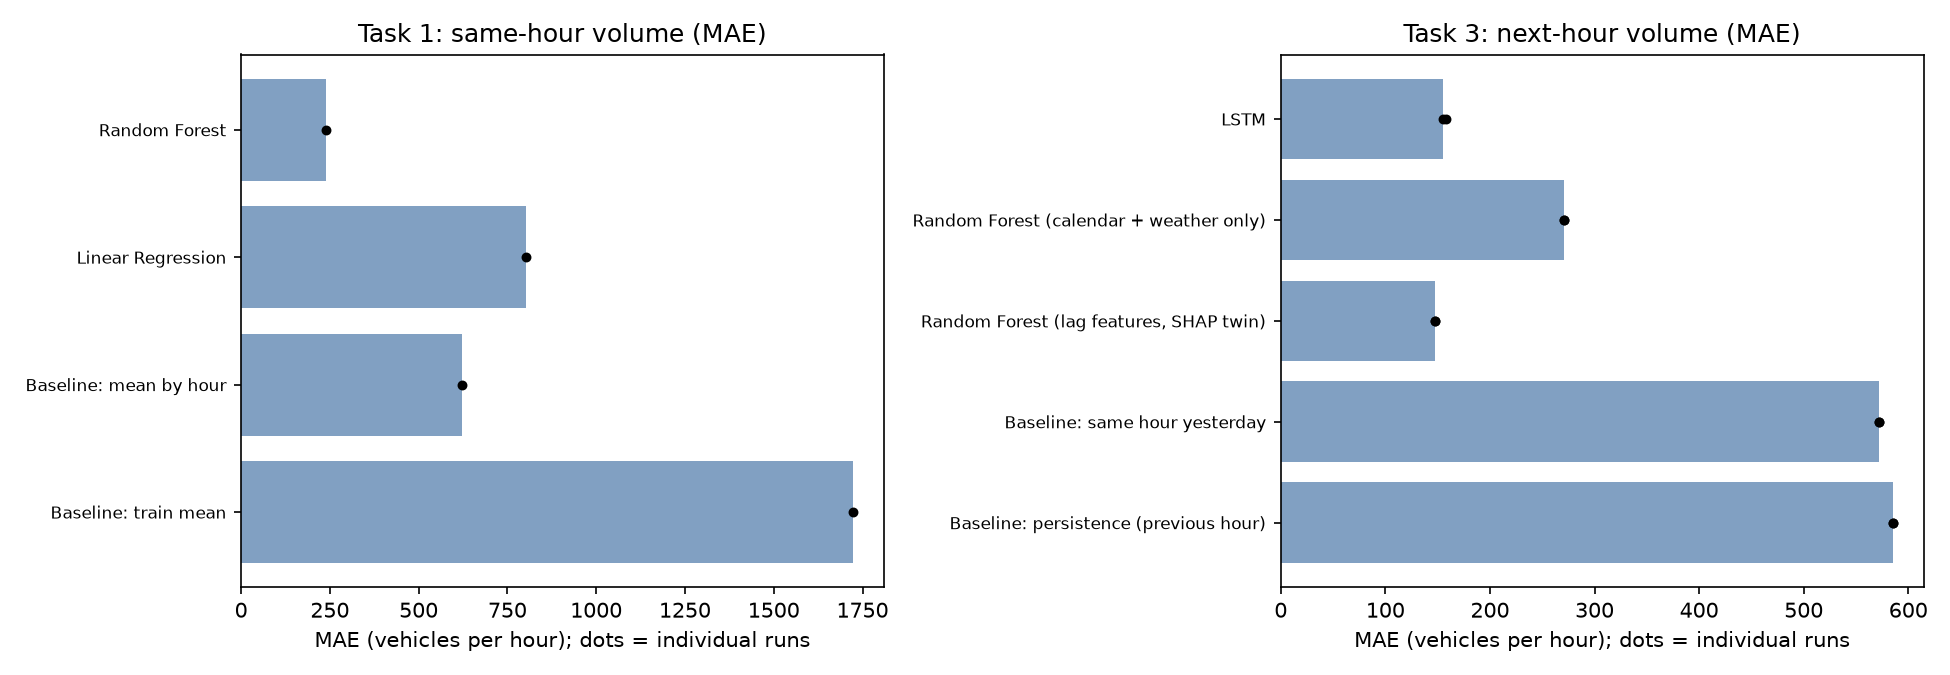

In [3]:
variability_path = OUT / "mlflow_rerun_variability.csv"
if not variability_path.exists():
    raise FileNotFoundError(f"Run mlflow_registry.py first; missing {variability_path}")
variability = pd.read_csv(variability_path)
display(variability)

chart_path = OUT / "mlflow_run_comparison.png"
if not chart_path.exists():
    raise FileNotFoundError(f"Run mlflow_registry.py first; missing {chart_path}")
display(Image(filename=str(chart_path)))

## 3. How it was implemented

- The newest run for each model is selected using test MAE for regression and test PR AUC for the proxy classifier. Baselines are excluded.
- Four models are registered: `traffic-volume-regressor`, `high-risk-classifier`, `next-hour-forecaster-rf`, and `next-hour-forecaster-lstm`.
- The Task 3 forest is logged as an MLflow scikit-learn model. The LSTM uses a pyfunc wrapper that packages its preprocessing metadata and accepts the 24-hour sequence and target-hour calendar inputs.
- The promotion gate loads each registered model and recomputes its logged test metric. Only versions within the configured tolerance get a `champion` or `challenger` alias.

This validates artifact loading and metric reproducibility on the current data; it is not evidence of production quality.

In [4]:
summary_path = OUT / "mlflow_registry_summary.csv"
if not summary_path.exists():
    raise FileNotFoundError(f"Run mlflow_registry.py first; missing {summary_path}")
registry_summary = pd.read_csv(summary_path)
display(registry_summary)

registered = client.search_registered_models()
for model in registered:
    if model.name.startswith(("traffic-volume-", "high-risk-", "next-hour-")):
        print(f"{model.name}: aliases={model.aliases}")
        for version in client.search_model_versions(f"name='{model.name}'"):
            print(f"  version={version.version}, source run={version.tags.get('source_run_id')}")

,registered_model,version,alias,source_run_id,metric,logged_value,registry_value,abs_difference,gate_passed,selection_rule
0,traffic-volume-regressor,1,champion,d6f25cbab87248bab73283482a2c0d12,MAE,238.87088,238.87088,0.0,True,lowest test MAE among latest non-baseline runs
1,high-risk-classifier,1,champion,c678035c7b844a49b0bb525a845e34c5,PR_AUC,0.95452,0.95452,0.0,True,"highest test PR AUC among latest non-baseline runs (proxy label, inflated by..."
2,next-hour-forecaster-rf,1,champion,d9540c598291499fa4d07afbf93e7c36,MAE,147.31975,147.31975,0.0,True,lowest test MAE among latest Task 3 forecasting models; the other model is t...
3,next-hour-forecaster-lstm,1,challenger,f9317d5be44742b2bc097434f7d38201,MAE,155.15738,155.15738,0.0,True,lowest test MAE among latest Task 3 forecasting models; the other model is t...


high-risk-classifier: aliases={'champion': 1}
  version=1, source run=c678035c7b844a49b0bb525a845e34c5
next-hour-forecaster-lstm: aliases={'challenger': 1}
  version=1, source run=f9317d5be44742b2bc097434f7d38201
next-hour-forecaster-rf: aliases={'champion': 1}
  version=1, source run=d9540c598291499fa4d07afbf93e7c36
traffic-volume-regressor: aliases={'champion': 1}
  version=1, source run=d6f25cbab87248bab73283482a2c0d12


## 4. Value and result

The registry provides stable, named references for serving, while the gate prevents an artifact that cannot reproduce its training metric from being promoted. The run audit also highlighted that the two logged LSTM runs had different test MAE (155.16 vs 158.38), while the forest reruns were much closer. The LSTM run difference is confounded by a change in weather imputation, so it cannot be attributed only to random training variation.

In the current registry, the Task 1 Random Forest regressor and classifier have `champion` aliases. The Task 3 lag-feature Random Forest is the next-hour forecasting `champion`; the LSTM is its `challenger`. Example loading calls:

```python
mlflow.sklearn.load_model("models:/traffic-volume-regressor@champion")
mlflow.pyfunc.load_model("models:/next-hour-forecaster-lstm@challenger")
```

## 5. Limitations

- Tracking uses a local SQLite database. The model artifacts are git-ignored; a fresh checkout needs Tasks 1–3 and Task 4 rerun before the registered models can be loaded.
- The dataset is not versioned. The gate uses current data and only checks that artifacts reproduce logged scores.
- Selection and gate checks use the test set, making the winning test metrics optimistic. A separate selection/validation set is needed for an unbiased final comparison.
- The `high_risk` classifier predicts a proxy label partly defined by weather features; its PR AUC is not accident-prediction skill.
- Alias updates are script-driven; this is not a human approval workflow and there is no production monitoring or automatic retraining.
- Registered artifacts use serialization formats that should only be loaded from a trusted source. The LSTM also depends on compatible TensorFlow/Keras versions.

The notebook is an inspection/reporting companion. Run `python Part-3/mlflow_registry.py` from the repository root to regenerate its audit tables, chart, registry versions, and aliases.